# Batch Airfoil JSON Processor

Processes a folder of airfoil JSON files (XFOIL/airfoiltools-style — geometry `xps/yps/xss/yss`
plus a `polars` list of `{Re, Ncrit, alpha, Cl, Cd, Cm, Cdp, Cp_ps, Cp_ss, ...}`) into clean,
ML-ready tables: one row per airfoil (geometry) and one row per (airfoil, Re, alpha) polar point.

**This notebook ships with one sample JSON already in `./sample_input/` so it runs immediately.**
When you're ready to process all ~825 of your files: change `INPUT_DIR` in the *Configuration*
cell below to the folder holding all of them, then **Run All** again.

### Outputs (written to `OUTPUT_DIR`)
| File | Contents |
|---|---|
| `airfoil_geometry.csv` | one row per airfoil: name, chord, max thickness %/position, max camber %/position |
| `geometry_coords.npz` | resampled `x`, `yps`, `yss` coordinate arrays per airfoil (for shape-based ML later) |
| `master_polars.csv` | one row per (airfoil, Re, alpha): `Re, log_Re, Ncrit, alpha, Cl, Cd, Cdp, Cm` + blank placeholder columns `AoA_sim, U0_sim, TAU_sim, Re_sim, Cl_sim, Cd_sim, Cm_sim, sim_status` for when you run your own LBM/Navier-Stokes sims later |
| `cp_data/<id>_<name>.npz` | full `Cp_ps` / `Cp_ss` pressure distributions per airfoil, linked back to `master_polars` via `polar_id` (kept separate — too large to put in the main CSV) |
| `failed_files.log` | any file that couldn't be parsed, with the reason — the batch keeps going regardless |

In [16]:
import json
import logging
import traceback
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Configuration

**Change `INPUT_DIR` to the folder with all ~825 of your JSON files, then re-run everything below.**

In [17]:
INPUT_DIR = "./json"     # <-- change to your folder of ~825 airfoil JSON files
OUTPUT_DIR = "./processed_new"

INCLUDE_CP = True        # also save full Cp_ps/Cp_ss pressure distributions (per-airfoil .npz files)
RESAMPLE_POINTS = 1000    # points per surface when resampling airfoil geometry
WORKERS = 1              # >1 uses multiple processes to speed up large batches

INPUT_DIR = Path(INPUT_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CP_DIR = OUTPUT_DIR / "cp_data"
if INCLUDE_CP:
    CP_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    filename=str(OUTPUT_DIR / "failed_files.log"),
    level=logging.INFO,
    format="%(asctime)s %(message)s",
    force=True,
)

print("Input dir :", INPUT_DIR.resolve())
print("Output dir:", OUTPUT_DIR.resolve())

Input dir : C:\Users\lavish\Desktop\AeroFoil\json
Output dir: C:\Users\lavish\Desktop\AeroFoil\processed_new


## Geometry feature extraction

In [18]:
def resample_side(x, y, x_common):
    """Linearly interpolate one surface (x increasing from 0 to chord) onto x_common."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    order = np.argsort(x)
    x, y = x[order], y[order]
    return np.interp(x_common, x, y)


def geometry_features(xps, yps, xss, yss, n_resample=100):
    """
    Compute standard airfoil shape descriptors from the pressure-side (ps) and
    suction-side (ss) coordinate arrays (each LE->TE, chord assumed ~1).
    Returns (feats: dict of scalar descriptors, coords: dict of resampled arrays).
    """
    xps = np.asarray(xps, dtype=float)
    xss = np.asarray(xss, dtype=float)

    x_le = min(xps.min(), xss.min())
    x_te = max(xps.max(), xss.max())
    chord = x_te - x_le if x_te > x_le else 1.0

    x_common = np.linspace(x_le, x_te, n_resample)
    yps_r = resample_side(xps, yps, x_common)
    yss_r = resample_side(xss, yss, x_common)

    thickness = (yss_r - yps_r) / chord
    camber = (yss_r + yps_r) / 2.0 / chord
    x_frac = (x_common - x_le) / chord  # 0..1 fraction of chord

    i_t = int(np.argmax(thickness))
    i_c = int(np.argmax(np.abs(camber)))

    feats = {
        "chord": float(chord),
        "max_thickness_percent": float(thickness[i_t] * 100.0),
        "max_thickness_position": float(x_frac[i_t] * 100.0),  # % chord
        "max_camber_percent": float(camber[i_c] * 100.0),
        "max_camber_position": float(x_frac[i_c] * 100.0),      # % chord
    }
    coords = {
        "x": x_frac.astype(np.float32),
        "yps": yps_r.astype(np.float32),
        "yss": yss_r.astype(np.float32),
    }
    return feats, coords

## Per-file parsing

In [19]:
def process_one_file(path_str, n_resample):
    """
    Parse a single airfoil JSON file. Returns:
      airfoil_row (dict), coords (dict), polar_rows (list[dict]),
      cp_ps (2D array or None), cp_ss (2D array or None), local_ids (list[int])
    Raises on failure -- caller handles logging so one bad file doesn't stop the batch.
    """
    path = Path(path_str)
    with open(path, "r") as f:
        data = json.load(f)

    name = data.get("name", path.stem)
    xps, yps = data["xps"], data["yps"]
    xss, yss = data["xss"], data["yss"]

    feats, coords = geometry_features(xps, yps, xss, yss, n_resample=n_resample)

    airfoil_row = {
        "airfoil_name": name,
        "source_file": path.name,
        "n_geom_points": len(xps),
        **feats,
    }

    polars = data.get("polars", [])
    polar_rows = []
    cp_ps_list, cp_ss_list, local_ids = [], [], []

    for local_id, p in enumerate(polars):
        Re = p.get("Re", np.nan)
        row = {
            "Re": Re,
            "log_Re": float(np.log10(Re)) if Re and Re > 0 else np.nan,
            "Ncrit": p.get("Ncrit", np.nan),
            "alpha": p.get("alpha", np.nan),
            "alpha_min": p.get("alpha_min", np.nan),
            "alpha_max": p.get("alpha_max", np.nan),
            "alpha_step": p.get("alpha_step", np.nan),
            "Cl": p.get("Cl", np.nan),
            "Cd": p.get("Cd", np.nan),
            "Cdp": p.get("Cdp", np.nan),
            "Cm": p.get("Cm", np.nan),
            "local_polar_id": local_id,
            # --- placeholders for YOUR future Navier-Stokes / LBM simulation runs ---
            "AoA_sim": np.nan,
            "U0_sim": np.nan,
            "TAU_sim": np.nan,
            "Re_sim": np.nan,
            "Cl_sim": np.nan,
            "Cd_sim": np.nan,
            "Cm_sim": np.nan,
            "sim_status": "pending",
        }
        polar_rows.append(row)

        if "Cp_ps" in p and "Cp_ss" in p:
            cp_ps_list.append(np.asarray(p["Cp_ps"], dtype=np.float32))
            cp_ss_list.append(np.asarray(p["Cp_ss"], dtype=np.float32))
            local_ids.append(local_id)

    cp_ps = np.vstack(cp_ps_list) if cp_ps_list else None
    cp_ss = np.vstack(cp_ss_list) if cp_ss_list else None

    return airfoil_row, coords, polar_rows, cp_ps, cp_ss, local_ids

## Run the batch

In [20]:
json_files = sorted(INPUT_DIR.rglob("*.json"))
n_total = len(json_files)
assert n_total > 0, f"No .json files found under {INPUT_DIR}"
print(f"Found {n_total} JSON files under {INPUT_DIR}")

airfoil_rows = []
all_polar_rows = []
coords_store = {}
global_polar_id = 0
n_failed = 0


def handle_result(airfoil_id, result):
    global global_polar_id
    airfoil_row, coords, polar_rows, cp_ps, cp_ss, local_ids = result
    airfoil_row["airfoil_id"] = airfoil_id
    airfoil_rows.append(airfoil_row)
    coords_store[airfoil_id] = coords

    polar_id_map = {}
    for row in polar_rows:
        row["airfoil_id"] = airfoil_id
        row["airfoil_name"] = airfoil_row["airfoil_name"]
        row["max_thickness_percent"] = airfoil_row["max_thickness_percent"]
        row["max_thickness_position"] = airfoil_row["max_thickness_position"]
        row["max_camber_percent"] = airfoil_row["max_camber_percent"]
        row["max_camber_position"] = airfoil_row["max_camber_position"]
        row["polar_id"] = global_polar_id
        polar_id_map[row["local_polar_id"]] = global_polar_id
        del row["local_polar_id"]
        all_polar_rows.append(row)
        global_polar_id += 1

    if INCLUDE_CP and cp_ps is not None:
        aligned_polar_ids = np.array([polar_id_map[i] for i in local_ids], dtype=np.int64)
        safe_name = "".join(c if c.isalnum() or c in "-_" else "_" for c in airfoil_row["airfoil_name"])[:80]
        out_path = CP_DIR / f"{airfoil_id:04d}_{safe_name}.npz"
        np.savez_compressed(out_path, polar_id=aligned_polar_ids, Cp_ps=cp_ps, Cp_ss=cp_ss)


if WORKERS <= 4:
    for airfoil_id, path in enumerate(json_files):
        try:
            result = process_one_file(str(path), RESAMPLE_POINTS)
            handle_result(airfoil_id, result)
        except Exception as e:
            n_failed += 1
            logging.info(f"FAILED {path.name}: {e}\n{traceback.format_exc()}")
        if (airfoil_id + 1) % 25 == 0 or (airfoil_id + 1) == n_total:
            print(f"  processed {airfoil_id + 1}/{n_total} files ({n_failed} failed so far)")
else:
    with ProcessPoolExecutor(max_workers=WORKERS) as ex:
        futures = {ex.submit(process_one_file, str(path), RESAMPLE_POINTS): (i, path)
                   for i, path in enumerate(json_files)}
        done = 0
        for fut in as_completed(futures):
            airfoil_id, path = futures[fut]
            done += 1
            try:
                result = fut.result()
                handle_result(airfoil_id, result)
            except Exception as e:
                n_failed += 1
                logging.info(f"FAILED {path.name}: {e}\n{traceback.format_exc()}")
            if done % 25 == 0 or done == n_total:
                print(f"  processed {done}/{n_total} files ({n_failed} failed so far)")

print(f"\nDone. {len(airfoil_rows)}/{n_total} airfoils processed successfully, {n_failed} failed.")

Found 825 JSON files under json
  processed 25/825 files (0 failed so far)
  processed 50/825 files (0 failed so far)
  processed 75/825 files (0 failed so far)
  processed 100/825 files (0 failed so far)
  processed 125/825 files (0 failed so far)
  processed 150/825 files (0 failed so far)
  processed 175/825 files (0 failed so far)
  processed 200/825 files (0 failed so far)
  processed 225/825 files (0 failed so far)
  processed 250/825 files (0 failed so far)
  processed 275/825 files (0 failed so far)
  processed 300/825 files (0 failed so far)
  processed 325/825 files (0 failed so far)
  processed 350/825 files (0 failed so far)
  processed 375/825 files (0 failed so far)
  processed 400/825 files (0 failed so far)
  processed 425/825 files (0 failed so far)
  processed 450/825 files (0 failed so far)
  processed 475/825 files (0 failed so far)
  processed 500/825 files (0 failed so far)
  processed 525/825 files (0 failed so far)
  processed 550/825 files (0 failed so far)
  p

## Save the output tables

In [21]:
# --- geometry table: one row per airfoil ---
geom_df = pd.DataFrame(airfoil_rows).sort_values("airfoil_id").reset_index(drop=True)
geom_cols = ["airfoil_id", "airfoil_name", "source_file", "n_geom_points", "chord",
             "max_thickness_percent", "max_thickness_position",
             "max_camber_percent", "max_camber_position"]
geom_df = geom_df[geom_cols]
geom_df.to_csv(OUTPUT_DIR / "airfoil_geometry.csv", index=False)

# --- resampled coordinate arrays (one npz for all airfoils) ---
coord_arrays = {}
for aid, c in coords_store.items():
    coord_arrays[f"{aid:04d}_x"] = c["x"]
    coord_arrays[f"{aid:04d}_yps"] = c["yps"]
    coord_arrays[f"{aid:04d}_yss"] = c["yss"]
np.savez_compressed(OUTPUT_DIR / "geometry_coords.npz", **coord_arrays)

# --- master tidy polar table: one row per (airfoil, Re, alpha) ---
polar_cols = [
    "polar_id", "airfoil_id", "airfoil_name",
    "max_thickness_percent", "max_thickness_position",
    "max_camber_percent", "max_camber_position",
    "Re", "log_Re", "Ncrit", "alpha", "alpha_min", "alpha_max", "alpha_step",
    "Cl", "Cd", "Cdp", "Cm",
    "AoA_sim", "U0_sim", "TAU_sim", "Re_sim", "Cl_sim", "Cd_sim", "Cm_sim", "sim_status",
]
polars_df = pd.DataFrame(all_polar_rows)[polar_cols]
polars_df.to_csv(OUTPUT_DIR / "master_polars.csv", index=False)

n_cp_files = len(list(CP_DIR.glob("*.npz"))) if INCLUDE_CP else 0
print("=" * 60)
print(f"Airfoils processed successfully   : {len(geom_df)} / {n_total}")
print(f"Failed files                      : {n_failed}  (see failed_files.log)")
print(f"Total polar rows (Re/alpha combos): {len(polars_df)}")
print(f"Output written to                 : {OUTPUT_DIR.resolve()}")
print("  - airfoil_geometry.csv")
print("  - geometry_coords.npz")
print("  - master_polars.csv")
if INCLUDE_CP:
    print(f"  - cp_data/  ({n_cp_files} files)")
print("=" * 60)

Airfoils processed successfully   : 825 / 825
Failed files                      : 0  (see failed_files.log)
Total polar rows (Re/alpha combos): 768542
Output written to                 : C:\Users\lavish\Desktop\AeroFoil\processed_new
  - airfoil_geometry.csv
  - geometry_coords.npz
  - master_polars.csv
  - cp_data/  (818 files)


## Quick look at the results

In [22]:
geom_df.head(10)

,airfoil_id,airfoil_name,source_file,n_geom_points,chord,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position
0,0,2032c-il - 20-32C AIRFOIL,2032c-il - 20-32C AIRFOIL.json,100,1.0,7.998877,18.218218,7.003057,35.335335
1,1,a18-il - A18 (original),a18-il - A18 (original).json,100,1.0,7.355841,29.229229,5.037132,44.444444
2,2,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL.json,100,1.0,7.734754,30.330330,0.551592,62.662663
3,3,ag04-il - AG04,ag04-il - AG04.json,100,1.0,6.423681,22.222222,1.752520,39.439439
4,4,ag09-il - AG09,ag09-il - AG09.json,100,1.0,4.862927,18.118118,1.858405,33.333333
5,5,ag11-il - AG11,ag11-il - AG11.json,100,1.0,5.812091,25.325325,2.288169,29.329329
6,6,ag13-il - AG13,ag13-il - AG13.json,100,1.0,5.834532,21.221221,1.974922,42.442442
7,7,ag16-il - AG16,ag16-il - AG16.json,100,1.0,7.114610,23.223223,1.870656,46.446446
8,8,ag18-il - AG18,ag18-il - AG18.json,100,1.0,5.868000,21.221221,2.162398,44.444444
9,9,ag24-il - AG24 Bubble Dancer DLG by Mark Drela,ag24-il - AG24 Bubble Dancer DLG by Mark Drela...,100,1.0,8.414886,26.326326,2.215188,45.445445


In [23]:
polars_df.head(10)

,polar_id,airfoil_id,airfoil_name,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,Ncrit,...,Cdp,Cm,AoA_sim,U0_sim,TAU_sim,Re_sim,Cl_sim,Cd_sim,Cm_sim,sim_status
0,0,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.09467,-0.0262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
1,1,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.10359,-0.0219,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
2,2,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.09935,-0.0213,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
3,3,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.09639,-0.0215,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
4,4,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.08980,-0.0166,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
5,5,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.08738,-0.0186,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
6,6,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.08281,-0.0268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
7,7,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.07814,-0.0361,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
8,8,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.07404,-0.0523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending
9,9,0,2032c-il - 20-32C AIRFOIL,7.998877,18.218218,7.003057,35.335335,200000.0,5.30103,9.0,...,0.06982,-0.0675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pending


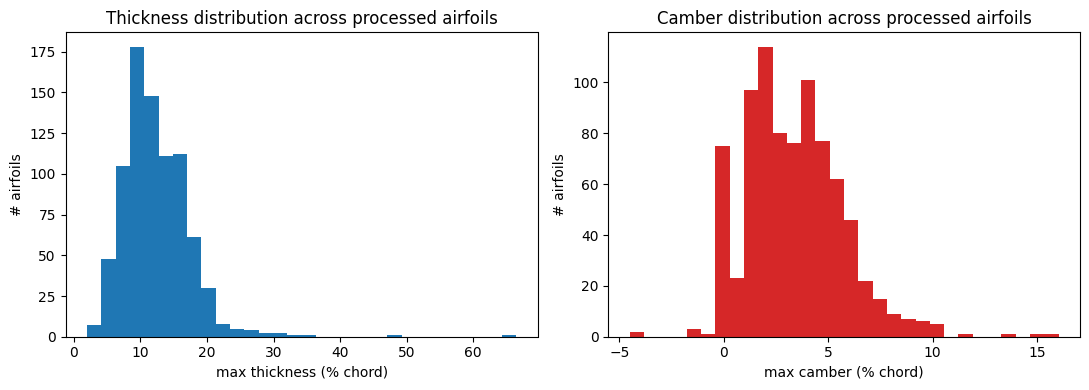

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(geom_df["max_thickness_percent"], bins=30, color="#1f77b4")
axes[0].set_xlabel("max thickness (% chord)"); axes[0].set_ylabel("# airfoils")
axes[0].set_title("Thickness distribution across processed airfoils")

axes[1].hist(geom_df["max_camber_percent"], bins=30, color="#d62728")
axes[1].set_xlabel("max camber (% chord)"); axes[1].set_ylabel("# airfoils")
axes[1].set_title("Camber distribution across processed airfoils")

plt.tight_layout()
plt.show()